In [26]:
%load_ext byname

The byname extension is already loaded. To reload it, use:
  %reload_ext byname


### What each weight in a relu layer does

explanation of the stacked linear layers and activations section in `exercises/test_round_1.pyn`

**1. Without relu, stacked layers collapse.** A linear layer of a linear layer is still one linear layer:

```
down(up(x)) = (x @ W1.T + b1) @ W2.T + b2
            = x @ (W2 @ W1).T + (W2 @ b1 + b2)
```

So depth adds parameters but no expressive power (`test_stacked_linear_layers_collapse_into_one_smaller_layer`).

**2. Each relu neuron is a ramp.** With one input and one output, neuron i does:

```
w_down · relu(w_up · x + b_up)
```

It's 0 on one side of a threshold and a straight ramp on the other. The output is the sum of these ramps plus b_down.

**3. The sign of `up` weight sets which side fires.** A positive w_up fires for x above the threshold, and a negative one fires below it. Its size scales the ramp, so relu(3x) climbs three times as fast as relu(x). `test_relu_lets_two_layers_compute_abs` uses w_up = 1 and −1:

```
|x| = relu(x) + relu(−x)
```

**4. `up` bias sets the threshold.** The neuron turns on where w_up · x + b_up = 0, which is at x = −b_up / w_up. With w_up = 1 that's x = −b_up, so bias −2 keeps the neuron off up to x = 2, and bias 2 has it on from x = −1 (`test_relu_bias_decides_where_each_neuron_turns_on`).

**5. `down` weight is the slope change at that neuron's bend.** Once a neuron turns on, it adds w_up · w_down to the slope and keeps adding it from there on. The slope in any region is the sum over the neurons that are on. With biases −2, −1, 0, 1, 2 and down weights 2, −2, 2, −2, 1:

```
x       −3  −2  −1   0   1   2   3
output   0   0   1   0   1   0   1
```

The first neuron to turn on gives slope +1, and each later one adds −2 or +2, so the slope flips and the output zigzags. There's a bend at each threshold, 5 in all.

**6. `down` bias shifts the whole output** up or down.

**7. In the model, x is a vector.** Each neuron's `up` row is then a direction, and the threshold w_up · x + b_up = 0 becomes a flat boundary (a hyperplane) that splits the input space. The neuron fires on one side of it. The feed-forward layer has 4E of these boundaries, and that's how it picks out different input patterns.


**8. A by-hand example.** up weight −1, 1, 1, up bias 0, 0, −2 and down weight 1, 1, 2 give the neurons relu(−x), relu(x) and 2 · relu(x − 2):

- x < 0, only relu(−x) is on, slope −1
- 0 to 2, only relu(x) is on, slope +1
- x > 2, relu(x) and 2 · relu(x − 2) are on, slope 1 + 2 = 3

```
x       −2  −1   0   1   2   3   4   5
output   2   1   0   1   2   5   8  11
```


x: -2 -1  0  1  2  3  4  5
y:  2  1  0  1  2  5  8 11


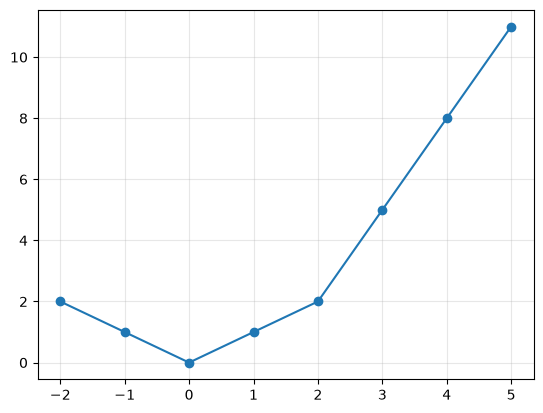

In [27]:
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from torch import nn

up = nn.Linear(1, 3)
down = nn.Linear(3, 1, bias=False)
with torch.no_grad():
    up.weight.copy_(torch.tensor([[-1.0], [1.0], [1.0]]))  # [3, 1]
    up.bias.copy_(torch.tensor([0.0, 0.0, -2.0]))  # [3]
    down.weight.copy_(torch.tensor([[1.0, 1.0, 2.0]]))  # [1, 3]

x = torch.arange(-2.0, 6.0).unsqueeze(-1)  # [8, 1], x = -2 .. 5
with torch.no_grad():
    y = down(F.relu(up(x)))  # [8, 1]
print("x:", " ".join([f"{v:2.0f}" for v in x.squeeze(-1)]))
print("y:", " ".join([f"{v:2.0f}" for v in y.squeeze(-1)]))
plt.plot(x, y, marker="o")
plt.grid(alpha=0.3)
plt.show()